In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [2]:
# Load the binary classification dataset
data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Class names:", data.target_names)
print("Class distribution:", np.bincount(y))

Dataset shape: (569, 30)
Target shape: (569,)
Class names: ['malignant' 'benign']
Class distribution: [212 357]


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

Training samples: 455
Testing samples: 114
Number of features: 30


In [4]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(30,)),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │            31 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31 (124.00 B)

 Trainable params: 31 (124.00 B)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [6]:
history = model.fit(
    X_train,
    y_train,
    epochs=25,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 118ms/step - accuracy: 0.6648 - loss: 0.6321 - val_accuracy: 0.6593 - val_loss: 0.5920
Epoch 2/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7060 - loss: 0.5769 - val_accuracy: 0.7033 - val_loss: 0.5455
Epoch 3/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7582 - loss: 0.5273 - val_accuracy: 0.7253 - val_loss: 0.5060
Epoch 4/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7912 - loss: 0.4867 - val_accuracy: 0.7802 - val_loss: 0.4722
Epoch 5/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8159 - loss: 0.4516 - val_accuracy: 0.8022 - val_loss: 0.4427
Epoch 6/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8434 - loss: 0.4227 - val_accuracy: 0.8462 - val_loss: 0.4162
Epoch 7/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8571 - loss: 0.3963 - val_accuracy: 0.8571 - val_loss: 0.3943
Epoch 8/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8654 - loss: 0.3750 - val_accuracy: 0.8901 - val_l

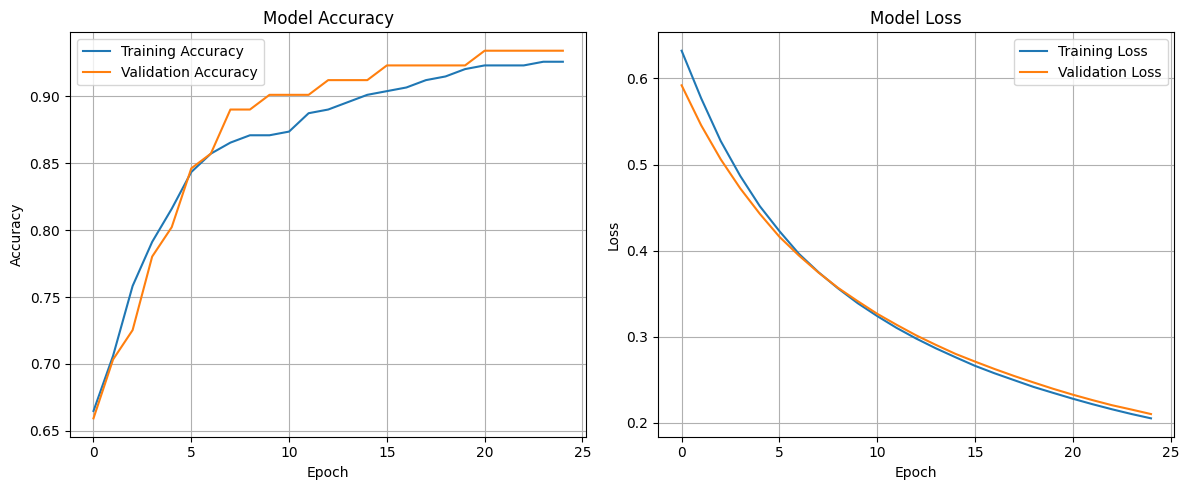

In [7]:
plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [8]:
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.2607
Test Accuracy: 86.84%


In [9]:
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Classification Report:

              precision    recall  f1-score   support

   malignant       0.76      0.93      0.84        42
      benign       0.95      0.83      0.89        72

    accuracy                           0.87       114
   macro avg       0.86      0.88      0.86       114
weighted avg       0.88      0.87      0.87       114

Confusion Matrix:
[[39  3]
 [12 60]]


In [10]:
!pip -q install gradio

In [11]:

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Calculate evaluation results
accuracy = accuracy_score(y_test, y_pred)

report = classification_report(
    y_test,
    y_pred,
    target_names=data.target_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose().round(3)
cm = confusion_matrix(y_test, y_pred)

# Create confusion matrix chart
fig_cm, ax_cm = plt.subplots(figsize=(5, 4))
ax_cm.imshow(cm, interpolation="nearest")
ax_cm.set_title("Confusion Matrix")
ax_cm.set_xlabel("Predicted Class")
ax_cm.set_ylabel("Actual Class")
ax_cm.set_xticks([0, 1])
ax_cm.set_yticks([0, 1])
ax_cm.set_xticklabels(data.target_names)
ax_cm.set_yticklabels(data.target_names)

for i in range(2):
    for j in range(2):
        ax_cm.text(j, i, str(cm[i, j]), ha="center", va="center")

fig_cm.tight_layout()

# Create training-performance charts
fig_train, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy over 25 Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss over 25 Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

fig_train.tight_layout()

# Build the website
with gr.Blocks(title="Single-Layer Perceptron Dashboard") as demo:
    gr.Markdown("""
    # Single-Layer Perceptron
    ### Binary Classification Dashboard

    **Dataset:** Breast Cancer Wisconsin
    **Framework:** TensorFlow and Keras
    **Architecture:** One sigmoid output neuron
    **Training:** 25 epochs
    """)

    with gr.Row():
        gr.Number(
            value=round(accuracy * 100, 2),
            label="Test Accuracy (%)",
            interactive=False
        )
        gr.Number(
            value=int((y_pred == y_test).sum()),
            label="Correct Predictions",
            interactive=False
        )
        gr.Number(
            value=int((y_pred != y_test).sum()),
            label="Incorrect Predictions",
            interactive=False
        )

    with gr.Tab("Classification Report"):
        gr.Dataframe(
            value=report_df,
            label="Precision, Recall, F1-score and Support",
            interactive=False
        )

    with gr.Tab("Confusion Matrix"):
        gr.Plot(value=fig_cm, label="Confusion Matrix")

    with gr.Tab("Training Performance"):
        gr.Plot(value=fig_train, label="Accuracy and Loss")

    gr.Markdown("""
    ### Conclusion
    The model was trained for 25 epochs and evaluated on unseen test data.
    Review the classification report and confusion matrix to understand
    its strengths and misclassifications.

    *This is an educational classification model, not a medical diagnostic tool.*
    """)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://84ca3081c2136d1121.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
